In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [10]:
data_path = "C:\\AI Equipment Failure Prediction\\lectures\\week9\\01_실습_20_261109_7\\01_실습\\01-03_열연_코일별_실습데이터.csv"
df = pd.read_csv(data_path)

In [11]:
df.shape

(1200, 11)

In [13]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df.dtypes

timestamp               datetime64[us]
coil_id                            str
coil_seq                         int64
position_pct                   float64
rolling_force_ton              float64
roll_gap_mm                    float64
exit_thickness_mm              float64
target_thickness_mm            float64
main_motor_current_a           float64
furnace_temp_c                 float64
roll_replaced                    int64
dtype: object

In [14]:
df.set_index('timestamp', inplace=True)
df.head()

,coil_id,coil_seq,position_pct,rolling_force_ton,roll_gap_mm,exit_thickness_mm,target_thickness_mm,main_motor_current_a,furnace_temp_c,roll_replaced
timestamp,,,,,,,,,,
2026-10-13 08:00:00,C001,1,0.0,914.1,2.0407,1.9857,2.0,1243.1,1242.2,0
2026-10-13 08:01:00,C001,1,3.4,912.1,2.0398,2.0065,2.0,1247.8,1244.1,0
2026-10-13 08:02:00,C001,1,6.9,916.6,2.0357,1.9991,2.0,1231.9,1245.2,0
2026-10-13 08:03:00,C001,1,10.3,905.3,2.0378,2.0064,2.0,1226.5,1234.9,0
2026-10-13 08:04:00,C001,1,13.8,917.2,2.0424,2.0004,2.0,1239.6,1241.7,0


In [16]:
df.isna().sum()

coil_id                 0
coil_seq                0
position_pct            0
rolling_force_ton       0
roll_gap_mm             0
exit_thickness_mm       0
target_thickness_mm     0
main_motor_current_a    0
furnace_temp_c          0
roll_replaced           0
dtype: int64

In [ ]:
# TODO 1: rolling_force_ton, roll_gap_mm, exit_thickness_mm 컬럼을
#         설비·역할·단위에 연결하는 표를 작성하세요.

In [20]:
df.head()

,coil_id,coil_seq,position_pct,rolling_force_ton,roll_gap_mm,exit_thickness_mm,target_thickness_mm,main_motor_current_a,furnace_temp_c,roll_replaced
timestamp,,,,,,,,,,
2026-10-13 08:00:00,C001,1,0.0,914.1,2.0407,1.9857,2.0,1243.1,1242.2,0
2026-10-13 08:01:00,C001,1,3.4,912.1,2.0398,2.0065,2.0,1247.8,1244.1,0
2026-10-13 08:02:00,C001,1,6.9,916.6,2.0357,1.9991,2.0,1231.9,1245.2,0
2026-10-13 08:03:00,C001,1,10.3,905.3,2.0378,2.0064,2.0,1226.5,1234.9,0
2026-10-13 08:04:00,C001,1,13.8,917.2,2.0424,2.0004,2.0,1239.6,1241.7,0


In [17]:
df.columns.tolist()

['coil_id',
 'coil_seq',
 'position_pct',
 'rolling_force_ton',
 'roll_gap_mm',
 'exit_thickness_mm',
 'target_thickness_mm',
 'main_motor_current_a',
 'furnace_temp_c',
 'roll_replaced']

In [19]:
#rolling_force_ton, roll_gap_mm, exit_thickness_mm 컬럼을
#         설비·역할·단위에 연결하는 표를 작성하세요.

column_info = pd.DataFrame(
    [
        ["rolling_force_ton", "압연기", "압연 하중", "ton"],
        ["roll_gap_mm", "압연기 롤", "롤 갭(조작량)", "mm"],
        ["exit_thickness_mm", "출측 두께계", "출측 두께(제어 대상)", "mm"],
    ],
    columns=["컬럼", "설비", "역할", "단위"],
)
column_info.head()



,컬럼,설비,역할,단위
0,rolling_force_ton,압연기,압연 하중,ton
1,roll_gap_mm,압연기 롤,롤 갭(조작량),mm
2,exit_thickness_mm,출측 두께계,출측 두께(제어 대상),mm


In [36]:
# TODO 2: 코일별 압연 하중 평균, 출측 두께 평균·표준편차를 집계하세요.

# 사용 컬럼
# coil_id
# rolling_force_ton
# exit_thickness_mm

In [64]:
df_col = df.groupby("coil_id").agg(
    rolling_force_ton_mean=("rolling_force_ton", "mean"),
    exit_thickness_mm_mean=("exit_thickness_mm", "mean"),
    exit_thickness_mm_std=("exit_thickness_mm", "std")
)

df_col.head()

,rolling_force_ton_mean,exit_thickness_mm_mean,exit_thickness_mm_std
coil_id,,,
C001,921.736667,1.998957,0.007828
C002,925.036667,1.999660,0.007261
C003,930.553333,2.000173,0.006468
C004,935.683333,1.999290,0.007635
C005,940.880000,2.000623,0.008932


## 컬럼 설명 

| 컬럼 | 설비·구분 | 의미 | 단위 | 자료형 |
|---|---|---|---|---|
| timestamp | 공통 | 측정 시각 (1분 간격, 인덱스로 사용) | 일시 | datetime64 |
| coil_id | 공통 | 코일 식별 번호 (C001~C040, 40개) | - | 문자열 |
| coil_seq | 공통 | 코일 생산 순번 (1~40) | - | int64 |
| position_pct | 공통 | 코일 길이 방향 위치 (0 = 시작, 100 = 끝) | % | float64 |
| rolling_force_ton | 압연기 | 압연 하중 (롤이 강판을 누르는 힘) | ton | float64 |
| roll_gap_mm | 압연기 롤 | 롤 사이 간격 (조작량) | mm | float64 |
| exit_thickness_mm | 출측 두께계 | 압연 후 실제 두께 (제어 대상) | mm | float64 |
| target_thickness_mm | 목표값 | 목표 두께 (설정값) | mm | float64 |
| main_motor_current_a | 주 모터 | 압연 주 모터 전류 (부하 지표) | A | float64 |
| furnace_temp_c | 가열로 | 가열로 온도 | ℃ | float64 |
| roll_replaced | 이벤트 | 롤 교체 여부 (0 = 미교체, 1 = 교체) | 0/1 | int64 |


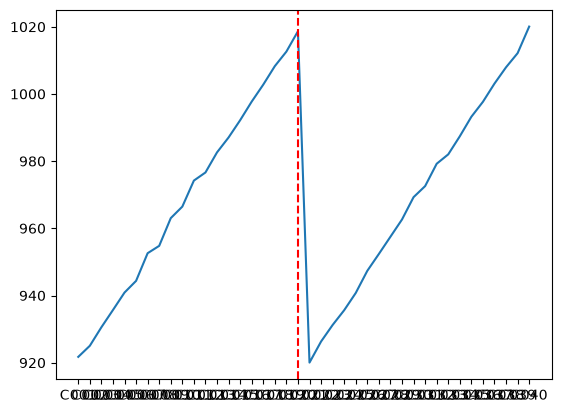

In [63]:
# TODO 3: 코일 순서에 따라 하중이 되돌아가는 지점과 두께 변동 구간을 찾으세요.

plt.plot(df_col.index, df_col['rolling_force_ton_mean'])
plt.axvline(x='C020', color='r', linestyle='--')
plt.show()


In [ ]:
#C020 기점 압연 하중이 떨어짐

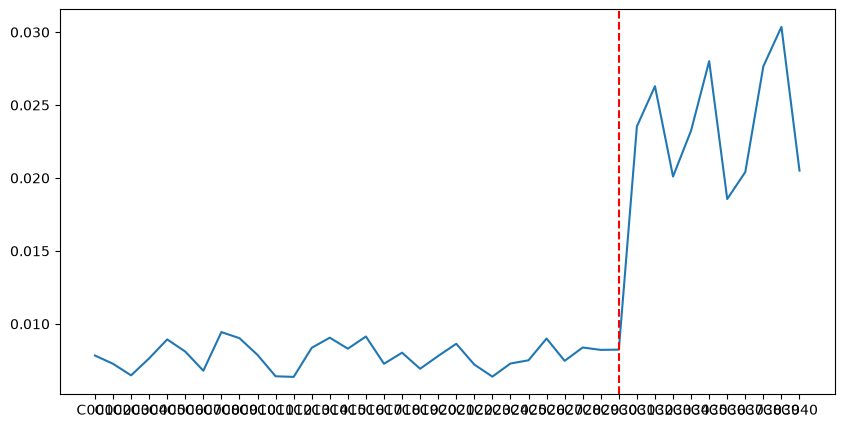

In [49]:
plt.figure(figsize=(10, 5))
plt.plot(df_col.index, df_col['exit_thickness_mm_std'])
plt.axvline(x='C030', color='r', linestyle='--')
plt.show()

In [50]:
#c030 기점으로 압연후 두께 의 표준편차가 증가함

In [53]:
# TODO 4: 롤 갭(조작량), 출측 두께(제어 대상), 모터 전류(상태값)를 구분하세요.


In [57]:
column_info = pd.DataFrame(
    [
        ["roll_gap_mm", "압연기 롤", "롤 갭(조작량)", "mm"],
        ["exit_thickness_mm", "출측 두께계", "출측 두께(제어 대상)", "mm"],
        ["main_motor_current_a", "주 모터", "모터 전류(상태값)", "A"],
    ],
    columns=["컬럼", "설비", "역할", "단위"],
)
column_info


,컬럼,설비,역할,단위
0,roll_gap_mm,압연기 롤,롤 갭(조작량),mm
1,exit_thickness_mm,출측 두께계,출측 두께(제어 대상),mm
2,main_motor_current_a,주 모터,모터 전류(상태값),A


In [58]:
# TODO 5: 값의 변화만으로 고장을 단정하지 말고 정비·AGC 이력을 확인하세요.



In [ ]:
# C020 이후 하중 감소, C030 이후 두께 표준편차 증가는 이상 징후일 뿐 고장 확정이 아님.
# 나의가설 : 하중 은 마모패턴 인거같고, 급락의 이유는 장비교체로 보임.

# 확인할 것: 정비 이력, 롤 교체(roll_replaced), AGC 설정·작동 이력, 가열로 온도
